In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Su empresa prepara la oferta a una licitación pública cuyo único criterio de adjudicación es el precio; el presupuesto base es de 920 k€ y el plazo de ejecución se fija en la oferta. El cuadro de prelaciones y las tres estimaciones de duración de cada actividad (semanas) proceden del equipo técnico; el coste estimado de ejecución es de 749 k€. Por experiencia en licitaciones anteriores se conocen las bajas (porcentaje de descuento sobre el presupuesto) que suelen presentar los tres competidores habituales.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a, m, b 
    ('A'     , '---'      , 6, 6, 12),
    ('B'     , '---'      , 1, 1, 1 ),
    ('C'     , 'A,B'      , 4, 5, 12),
    ('D'     , 'B'        , 2, 8, 8 ),
    ('E'     , 'B'        , 1, 2, 3 ),
    ('F'     , 'D,E'      , 1, 2, 3 ),
    ('G'     , 'F'        , 1, 3, 5 ),
    ('H'     , 'C,D'      , 1, 2, 3 ),
    ('I'     , 'F,H'      , 1, 1, 1 ),
], columns=['activity', 'predecessor', 'a', 'm', 'b']).set_index('activity')
datos_enunciado

,predecessor,a,m,b
activity,,,,
A,---,6,6,12
B,---,1,1,1
C,"A,B",4,5,12
D,B,2,8,8
E,B,1,2,3
F,"D,E",1,2,3
G,F,1,3,5
H,"C,D",1,2,3
I,"F,H",1,1,1


In [5]:
#| tbl-cap: "Bajas habituales de los competidores"
#| label: tbl-ofertas
bajas_competidores = pd.DataFrame([
#  oferta        , baja (%)
    ('Competidor 1', 14.6    ),
    ('Competidor 2', 12.3    ),
    ('Competidor 3', 15.6    ),
], columns=['oferta', 'baja (%)']).set_index('oferta')
bajas_competidores

,baja (%)
oferta,
Competidor 1,14.6
Competidor 2,12.3
Competidor 3,15.6


> **De: Director comercial**
> Vamos con una baja del 29.0 % y un plazo de 14 semanas: así ganamos seguro. Ya sé que el equipo dice que no llega; cuando estemos dentro se renegocia con modificados y prórrogas, como siempre.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C13 — Compromisos de buena fe.** Prometer un plazo o un precio que se sabe inalcanzable, contando con renegociarlo después, es un compromiso que no se hace de buena fe. *(cf. Código Ético del PMI, 5.2.4 y 2.2.3.)*
- **C1 — Afirmación falsa.** Comunicar como cierto un dato que quien lo comunica sabe que no lo es (un porcentaje de avance, una causa, una oferta que no existe). *(cf. Código Ético del PMI, estándar obligatorio 5.3.1; ICB4, Personas 2 «integridad personal y fiabilidad».)*
- **Norma — presunción de oferta anormalmente baja cuando el único criterio es el precio: un licitador, baja superior a 25 puntos sobre el presupuesto; dos, la que sea inferior en más de 20 puntos a la otra; tres o más, las inferiores en más de 10 puntos a la media de las ofertas (dejando fuera de la media las ofertas superiores a ella en más de 10 puntos y, si quedan menos de tres, tomando las tres más bajas). La presunción obliga a pedir justificación y, si no convence, a excluir la oferta** *(Reglamento general de la Ley de Contratos (RD 1098/2001), art. 85; LCSP art. 149.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [6]:
pregunta_1 = "1. (A) Con las cuatro ofertas (los tres competidores y la nuestra), calcule la media de las bajas con la regla de exclusión de ofertas altas y el umbral a partir del cual una oferta se presume anormalmente baja. ¿Incurre la nuestra en la presunción? ¿Qué margen deja el precio ofertado sobre el coste estimado?  "
pregunta_2 = "2. (A) Calcule la probabilidad de ejecutar en 14 semanas con la aproximación normal del PERT, y el plazo que se podría ofertar con una probabilidad de 0,8.  "
pregunta_3 = "3. (B) Según la norma y los criterios de referencia, ¿qué consecuencia tiene la presunción de anormalidad? ¿Qué incumple ofertar un plazo que se sabe inalcanzable contando con renegociarlo?  "
pregunta_4 = "4. (C) ¿Qué oferta (precio y plazo) propondría y cómo lo defendería ante el director comercial? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Con las cuatro ofertas (los tres competidores y la nuestra), calcule la media de las bajas con la regla de exclusión de ofertas altas y el umbral a partir del cual una oferta se presume anormalmente baja. ¿Incurre la nuestra en la presunción? ¿Qué margen deja el precio ofertado sobre el coste estimado?  

2. (A) Calcule la probabilidad de ejecutar en 14 semanas con la aproximación normal del PERT, y el plazo que se podría ofertar con una probabilidad de 0,8.  

3. (B) Según la norma y los criterios de referencia, ¿qué consecuencia tiene la presunción de anormalidad? ¿Qué incumple ofertar un plazo que se sabe inalcanzable contando con renegociarlo?  

4. (C) ¿Qué oferta (precio y plazo) propondría y cómo lo defendería ante el director comercial? Aplique la rúbrica.  

# Resolución

In [7]:
presupuesto, coste_estimado, baja_propuesta, plazo_oferta = 920, 749.0, 29.0, 14
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = (datos_proyecto['a'] + 4 * datos_proyecto['m'] + datos_proyecto['b']) / 6
datos_proyecto['standard_deviation'] = (datos_proyecto['b'] - datos_proyecto['a']) / 6
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion = float(proyecto.duration(datos_proyecto['duration']))
sigma, _ = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

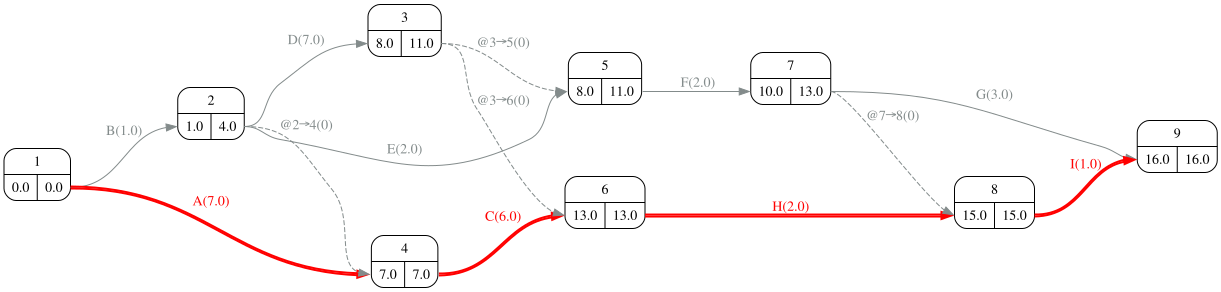

In [9]:
#| fig-cap: "Grafo PERT con las duraciones medias"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [10]:
display(Markdown(pregunta_1))

1. (A) Con las cuatro ofertas (los tres competidores y la nuestra), calcule la media de las bajas con la regla de exclusión de ofertas altas y el umbral a partir del cual una oferta se presume anormalmente baja. ¿Incurre la nuestra en la presunción? ¿Qué margen deja el precio ofertado sobre el coste estimado?  

In [11]:
def umbral_temeridad(bajas):
    '''Cuatro o más licitadores (art. 85.4 RGLCAP): media de las bajas sin las ofertas que superan la media en más
    de 10 puntos (bajas 10 puntos menores que la media); si quedan menos de tres, media de las tres ofertas más bajas.'''
    bajas = np.asarray(bajas, dtype=float)
    media = bajas.mean()
    altas = bajas < media - 10
    if altas.any():
        resto = bajas[~altas]
        if len(resto) < 3:
            resto = np.sort(bajas)[-3:]
        media = resto.mean()
    return media + 10, media
bajas = bajas_competidores['baja (%)'].tolist() + [baja_propuesta]
umbral, media = umbral_temeridad(bajas)
precio_oferta = presupuesto * (1 - baja_propuesta / 100)
margen = precio_oferta - coste_estimado
Markdown(f'''Bajas: {bajas}; media {media:.2f} %; umbral de presunción: media + 10 = **{umbral:.2f} %**. Nuestra baja del {baja_propuesta} % {'**supera** el umbral: se presume anormalmente baja' if baja_propuesta > umbral else 'no supera el umbral'}. Precio ofertado {precio_oferta:.1f} k€ frente a un coste estimado de {coste_estimado} k€: margen **{margen:+.1f} k€**.''')

Bajas: [14.6, 12.3, 15.6, 29.0]; media 17.88 %; umbral de presunción: media + 10 = **27.88 %**. Nuestra baja del 29.0 % **supera** el umbral: se presume anormalmente baja. Precio ofertado 653.2 k€ frente a un coste estimado de 749.0 k€: margen **-95.8 k€**.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. (A) Calcule la probabilidad de ejecutar en 14 semanas con la aproximación normal del PERT, y el plazo que se podría ofertar con una probabilidad de 0,8.  

In [13]:
z = (plazo_oferta - duracion) / sigma
p_plazo = float(norm.cdf(z))
plazo_80 = duracion + norm.ppf(0.8) * sigma
Markdown(f'''Duración esperada {duracion:.1f} semanas, σ = {sigma:.2f}: **P(T ≤ {plazo_oferta}) = {p_plazo:.2f}**. Con probabilidad 0,8 se cumplirían **{plazo_80:.1f}** semanas.''')

Duración esperada 16.0 semanas, σ = 1.70: **P(T ≤ 14) = 0.12**. Con probabilidad 0,8 se cumplirían **17.4** semanas.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) Según la norma y los criterios de referencia, ¿qué consecuencia tiene la presunción de anormalidad? ¿Qué incumple ofertar un plazo que se sabe inalcanzable contando con renegociarlo?  

**Norma.** La presunción de anormalidad obliga a la mesa a pedir justificación de la oferta; si la justificación no acredita que se puede ejecutar a ese precio (con un margen de -96 k€ sobre el coste, difícilmente), la oferta se excluye. «Ganar seguro» no es, por tanto, lo que ocurre. **C13.** Ofertar 14 semanas con una probabilidad del 12% de cumplirlas, contando con renegociar, es un compromiso que no se hace de buena fe; y **C1**: la oferta afirma un plazo que quien la firma sabe que no es el que espera cumplir. Que «siempre se haga» no cambia el criterio; y los modificados y prórrogas de la LCSP tienen causas tasadas, entre las que no está «ofertamos lo que no podíamos».

In [15]:
preguntas_test = [
    ('Con cuatro o más licitadores y sólo el precio como criterio, se presume anormal la oferta que…', ['baja más de 10 puntos por debajo de la media de las ofertas', 'es la más baja', 'baja más del 25 %', 'baja más de 20 puntos que la siguiente'],
     'Art. 85.4 RGLCAP, con la regla de exclusión de las ofertas altas.'),
    ('La consecuencia de la presunción de anormalidad es…', ['pedir justificación y excluir si no convence', 'la exclusión automática', 'la adjudicación con penalidad', 'ninguna si el licitador es solvente'],
     'La presunción abre un trámite de justificación; no es automática ni inocua.'),
    ('Ofertar un plazo que se sabe inalcanzable contando con renegociarlo es…', ['C13: compromiso sin buena fe (y C1)', 'C4: retención de información', 'una práctica comercial legítima', 'C8: reserva declarada'],
     'El compromiso se asume sabiendo que no se va a cumplir.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — oferta temeraria')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — oferta temeraria

::Ética 19 — oferta temeraria P1::Con cuatro o más licitadores y sólo el precio como criterio, se presume anormal la oferta que… {=baja más de 10 puntos por debajo de la media de las ofertas ~es la más baja ~baja más del 25 % ~baja más de 20 puntos que la siguiente ####Art. 85.4 RGLCAP, con la regla de exclusión de las ofertas altas.}

::Ética 19 — oferta temeraria P2::La consecuencia de la presunción de anormalidad es… {~ninguna si el licitador es solvente =pedir justificación y excluir si no convence ~la adjudicación con penalidad ~la exclusión automática ####La presunción abre un trámite de justificación; no es automática ni inocua.}

::Ética 19 — oferta temeraria P3::Ofertar un plazo que se sabe inalcanzable contando con renegociarlo es… {~C8: reserva declarada =C13: compromiso sin buena fe (y C1) ~C4: retención de información ~una práctica comercial legítima ####El compromiso se asume sabiendo que no se va a cumplir.}



## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) ¿Qué oferta (precio y plazo) propondría y cómo lo defendería ante el director comercial? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Oferta defendible: una baja por debajo del umbral (27.9 %) que deje margen sobre el coste, y el plazo que se puede cumplir con un 80 % (17 semanas), o 16 con la reserva declarada; si el plazo corto es decisivo, con el coste de comprimirlo (lección 10) dentro del precio. Al director comercial: la oferta temeraria se puede quedar fuera en la mesa, y si entra, los modificados no cubren un plazo que no se podía cumplir: el 88% de retraso se paga en penalidades y reputación. Prueba de publicidad: ¿firmaría la oferta si la mesa pudiera leer el correo del director comercial?